# Interpolación: lineal a tramos, Lagrange y splines cúbicas

Proyecto inicial para mostrar cómo funcionan, en qué se diferencian y cuándo fallan distintos métodos de interpolación.

Interpolar es estimar un valor que no medimos, pero que está entre datos que sí conocemos. Es como tener una foto tuya en cada cumpleaños y querer saber cuánto medías a medio año: no hay foto de ese día, pero puedes hacer una buena estimación usando las fotos de antes y de después.

En este notebook veremos tres formas de hacerlo, sus problemas y cómo se comportan con datos reales:

- Interpolación lineal a tramos
- Polinomio de Lagrange
- Splines cúbicas
- Fenómeno de Runge
- El pato: un ejemplo clásico de splines
- Práctica con datos reales: temperatura diaria en Melbourne
- Campos de aplicación

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline


# Los datos de ejemplo

Para comparar los tres interpoladores usaremos siempre los mismos puntos. Tomamos 6 puntos de la función $f(x) = \sin(x)$ entre $0$ y $2\pi$ y fingimos que no conocemos la función: solo tenemos esos 6 datos.

La pregunta es siempre la misma: ¿qué valor le asignamos a un $x$ que cae entre dos datos?

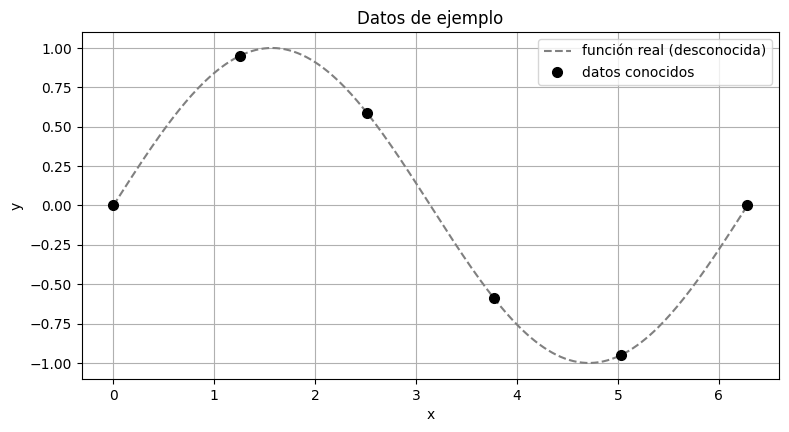

In [9]:
#función "verdadera", que en la vida real no conoceríamos
def f(x):
    return np.sin(x)

#6 puntos conocidos (nodos)
x_pts = np.linspace(0, 2*np.pi, 6)
y_pts = f(x_pts)

#muchos valores de x para dibujar curvas suaves
x_vals = np.linspace(0, 2*np.pi, 300)

plt.plot(x_vals, f(x_vals), color='gray', linestyle='dashed', label='función real (desconocida)')
plt.plot(x_pts, y_pts, 'o', color='black', markersize=7, label='datos conocidos')
plt.title('Datos de ejemplo')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

# Interpolación lineal a tramos

La idea más sencilla: unir cada par de puntos vecinos con una línea recta. Es lo que haces cuando dibujas una gráfica a mano y unes los puntos con regla.

Si $x$ está entre dos datos $(x_k, y_k)$ y $(x_{k+1}, y_{k+1})$, la recta que los une es

$$
P(x) = y_k + \frac{y_{k+1} - y_k}{x_{k+1} - x_k}\,(x - x_k).
$$

La fracción es la pendiente: cuánto sube $y$ por cada paso en $x$. Entonces empezamos en $y_k$ y avanzamos con esa pendiente hasta llegar a $x$.

Ejemplo. Si a las 8:00 hacía 10 grados y a las 10:00 hacía 14 grados, la pendiente es $(14-10)/(10-8) = 2$ grados por hora. A las 9:00 estimamos $10 + 2 \cdot 1 = 12$ grados.

Ventajas: es rápida, fácil de entender y nunca se inventa subidas o bajadas raras. Desventaja: en cada dato la curva hace una esquina, así que no es suave.

En numpy se hace con una sola función: `np.interp`.

Temperatura estimada a las 9:00 = 12.0


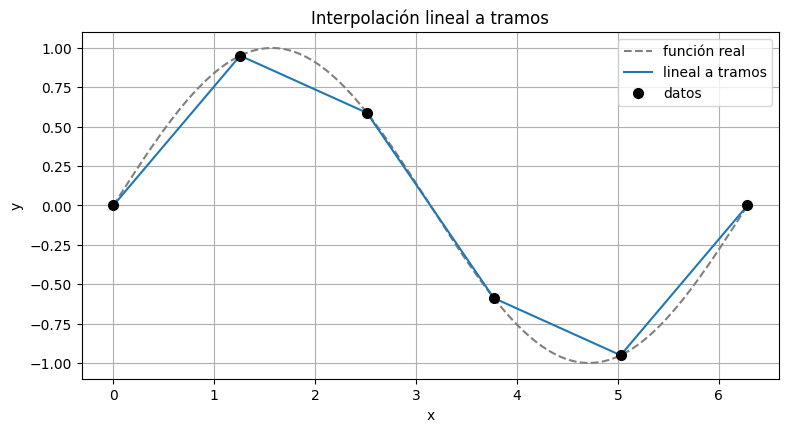

In [31]:
#interpolación lineal a tramos
y_lineal = np.interp(x_vals, x_pts, y_pts)

#comprobamos el ejemplo de la temperatura
print('Temperatura estimada a las 9:00 =', np.interp(9, [8, 10], [10, 14]))

plt.plot(x_vals, f(x_vals), color='gray', linestyle='dashed', label='función real')
plt.plot(x_vals, y_lineal, color='tab:blue', label='lineal a tramos')
plt.plot(x_pts, y_pts, 'o', color='black', markersize=7, label='datos')
plt.title('Interpolación lineal a tramos')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

La curva azul pasa por todos los datos, pero se nota que está hecha de segmentos rectos: en los picos de la función real (cerca de $x = \pi/2$ y $x = 3\pi/2$) la recta corta camino y se queda corta.

# Polinomio de Lagrange

En lugar de muchas rectas, ahora buscamos un solo polinomio que pase por todos los puntos. Con $n+1$ puntos siempre existe un único polinomio de grado a lo más $n$ que lo logra.

Lagrange lo construye con "interruptores". Para cada punto $x_k$ se arma un polinomio $\ell_k(x)$ que vale 1 en $x_k$ y 0 en todos los demás puntos:

$$
\ell_k(x) = \prod_{j \neq k} \frac{x - x_j}{x_k - x_j}.
$$

El símbolo $\prod$ significa "multiplica todos los factores", así como $\sum$ significa "suma todos los términos". El numerador se hace cero en cualquier otro punto $x_j$, y el denominador hace que el resultado valga exactamente 1 en $x_k$.

Después se suman los interruptores, cada uno multiplicado por su valor:

$$
p(x) = \sum_{k=0}^{n} y_k\,\ell_k(x).
$$

En cada dato se "enciende" solo su propio interruptor, por eso $p(x_k) = y_k$.

Ejemplo. Con los puntos $(2, 4)$ y $(5, 1)$: $\ell_0(x) = (x-5)/(2-5)$ y $\ell_1(x) = (x-2)/(5-2)$. Al sumar $4\,\ell_0(x) + 1\,\ell_1(x)$ y simplificar queda $p(x) = -x + 6$, que efectivamente vale 4 en $x=2$ y 1 en $x=5$.

Programamos las dos fórmulas tal cual.

In [32]:
def lk(val, k, x_pts):
    ''' Interruptor l_k de Lagrange evaluado en val '''
    res = 1.0
    for j in range(len(x_pts)):
        if j != k:
            res = res * (val - x_pts[j]) / (x_pts[k] - x_pts[j])
    return res

def p_Lagrange(val, x_pts, y_pts):
    ''' Polinomio de Lagrange evaluado en val '''
    res = 0.0
    for k in range(len(x_pts)):
        res = res + y_pts[k] * lk(val, k, x_pts)
    return res

#comprobamos el ejemplo de los puntos (2, 4) y (5, 1)
print('p(2) =', p_Lagrange(2, [2, 5], [4, 1]), '  p(5) =', p_Lagrange(5, [2, 5], [4, 1]), '  p(3) =', p_Lagrange(3, [2, 5], [4, 1]))

p(2) = 4.0   p(5) = 1.0   p(3) = 3.0


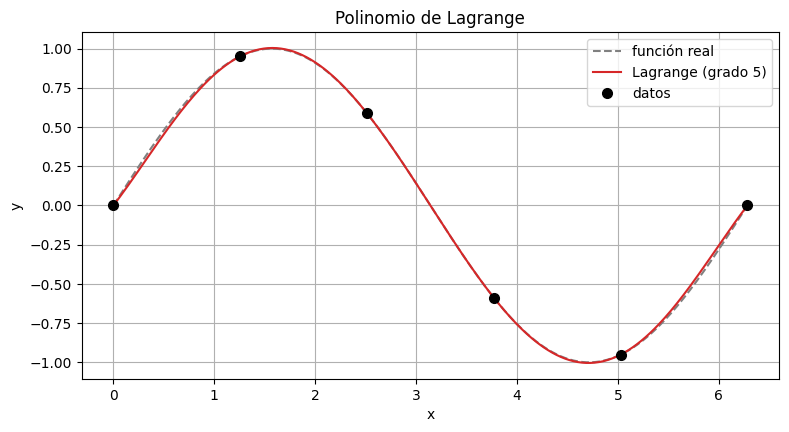

In [33]:
y_lagrange = p_Lagrange(x_vals, x_pts, y_pts)

plt.plot(x_vals, f(x_vals), color='gray', linestyle='dashed', label='función real')
plt.plot(x_vals, y_lagrange, color='tab:red', label='Lagrange (grado 5)')
plt.plot(x_pts, y_pts, 'o', color='black', markersize=7, label='datos')
plt.title('Polinomio de Lagrange')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

Con solo 6 puntos el polinomio de grado 5 es suave y se parece mucho a la función real. Parece la solución perfecta. En la sección 5 veremos que no siempre es así.

# Splines cúbicas

La spline cúbica combina lo mejor de los dos métodos anteriores: trabaja por tramos, como la lineal, pero en cada tramo usa una cúbica en vez de una recta.

El nombre viene de una tira delgada y flexible de madera que usaban los dibujantes. Clavaban la tira en los puntos y la madera se doblaba sola, formando la curva más suave posible que pasara por ellos.

En el tramo entre $x_j$ y $x_{j+1}$ la spline es

$$
S_j(x) = a_j + b_j(x - x_j) + c_j(x - x_j)^2 + d_j(x - x_j)^3.
$$

Los coeficientes se eligen para que, en cada punto donde se unen dos tramos, las piezas empalmen:

- misma altura: la curva no se rompe,
- misma pendiente ($S'$): no hay esquinas,
- misma curvatura ($S''$): la forma en que se dobla tampoco cambia de golpe.

Es como unir dos tramos de carretera: no basta con que se toquen, también deben ir en la misma dirección para que el coche no se salga.

Faltan dos condiciones en los extremos. La spline natural pide $S''(x_0) = S''(x_n) = 0$: la tira queda suelta en las puntas.

En scipy: `CubicSpline(x, y, bc_type='natural')`.

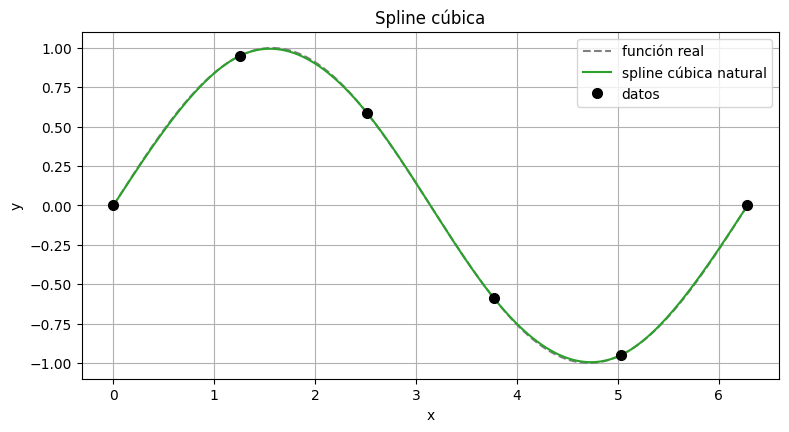

In [34]:
spline = CubicSpline(x_pts, y_pts, bc_type='natural')
y_spline = spline(x_vals)

plt.plot(x_vals, f(x_vals), color='gray', linestyle='dashed', label='función real')
plt.plot(x_vals, y_spline, color='tab:green', label='spline cúbica natural')
plt.plot(x_pts, y_pts, 'o', color='black', markersize=7, label='datos')
plt.title('Spline cúbica')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

##  Los tres juntos

Medimos qué tan lejos queda cada interpolador de la función real con el error cuadrático medio (ECM), que usaremos también en la práctica final:

$$
\text{ECM} = \frac{1}{m}\sum_{i=1}^{m}\left(y_i - \hat{y}_i\right)^2,
$$

donde $y_i$ es el valor real, $\hat{y}_i$ el valor estimado y $m$ el número de valores que comparamos. Se eleva al cuadrado para que los errores hacia arriba y hacia abajo no se cancelen, y para castigar más los errores grandes. Entre más cerca de cero, mejor.

lineal a tramos  ECM = 0.00966
Lagrange         ECM = 0.00013
spline cúbica    ECM = 0.00002


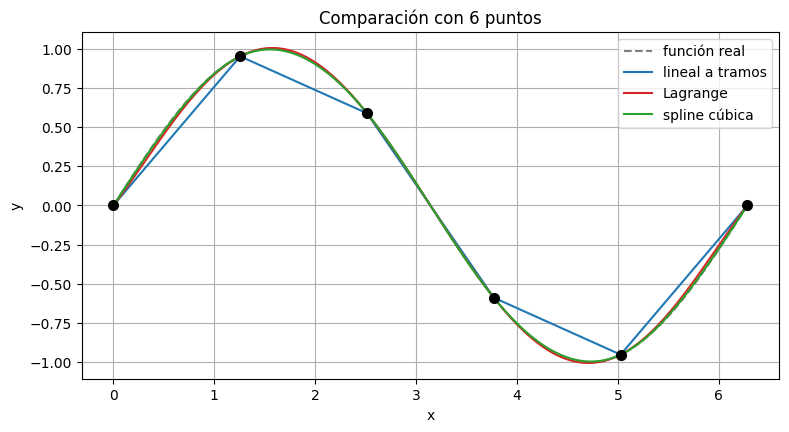

In [35]:
def ecm(y_real, y_estimado):
    ''' Error cuadrático medio '''
    return np.mean((y_real - y_estimado)**2)

for nombre, y_est in [('lineal a tramos', y_lineal), ('Lagrange', y_lagrange), ('spline cúbica', y_spline)]:
    print('{:16s} ECM = {:.5f}'.format(nombre, ecm(f(x_vals), y_est)))

plt.plot(x_vals, f(x_vals), color='gray', linestyle='dashed', label='función real')
plt.plot(x_vals, y_lineal, color='tab:blue', label='lineal a tramos')
plt.plot(x_vals, y_lagrange, color='tab:red', label='Lagrange')
plt.plot(x_vals, y_spline, color='tab:green', label='spline cúbica')
plt.plot(x_pts, y_pts, 'o', color='black', markersize=7)
plt.title('Comparación con 6 puntos')
plt.xlabel('x')
plt.ylabel('y')
plt.legend()
plt.show()

Con pocos puntos de una función suave, Lagrange y la spline quedan muy cerca de la función real y la lineal a tramos es la que más se equivoca, porque no puede seguir las curvas.

#  Fenómeno de Runge

Uno pensaría que con más puntos el polinomio de Lagrange siempre se acerca más a la función. Carl Runge mostró en 1901 que esto es falso usando la función

$$
f(x) = \frac{1}{1 + 25x^2}, \qquad x \in [-1, 1].
$$

Si tomamos puntos igualmente espaciados y aumentamos su número, el polinomio se pega a la función en el centro, pero cerca de los bordes empieza a oscilar cada vez con más fuerza.

La razón: un polinomio de grado alto está obligado a pasar exactamente por todos los puntos y, para lograrlo, se retuerce. Es como intentar pasar un hilo muy tenso por muchos clavos: en medio se acomoda, pero en las puntas latiguea.


n =  5   error máximo Lagrange =    0.433   error máximo spline = 0.423
n = 10   error máximo Lagrange =    1.916   error máximo spline = 0.022
n = 15   error máximo Lagrange =    2.104   error máximo spline = 0.031


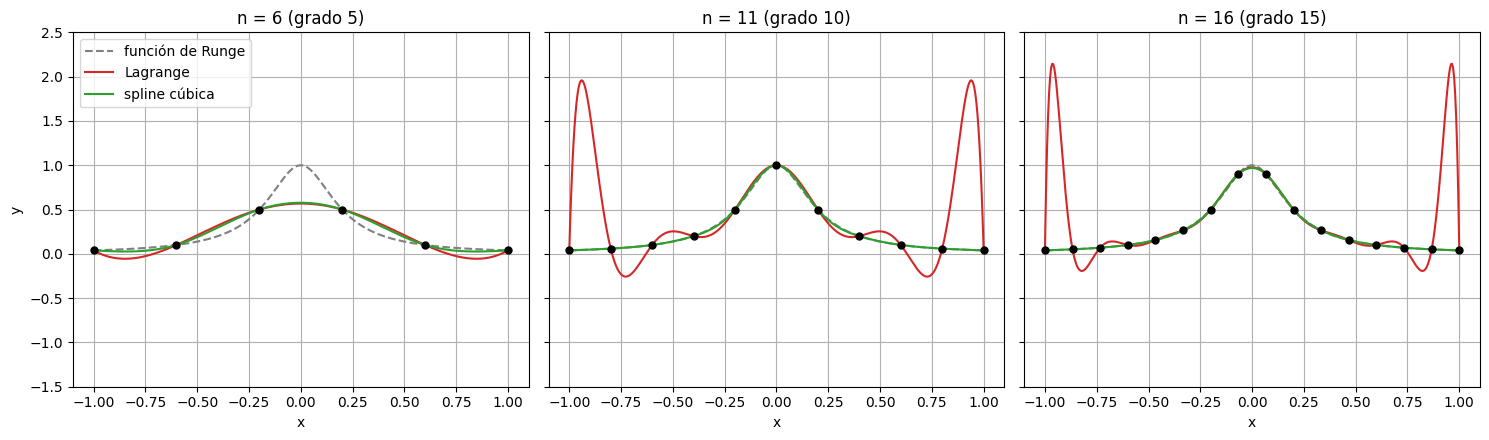

In [36]:
def runge(x):
    return 1 / (1 + 25*x**2)

x_fino = np.linspace(-1, 1, 400)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for eje, n in zip(ejes, [5, 10, 15]):
    #n+1 puntos igualmente espaciados
    xr = np.linspace(-1, 1, n + 1)
    yr = runge(xr)
    y_lag = p_Lagrange(x_fino, xr, yr)
    y_spl = CubicSpline(xr, yr, bc_type='natural')(x_fino)

    eje.plot(x_fino, runge(x_fino), color='gray', linestyle='dashed', label='función de Runge')
    eje.plot(x_fino, y_lag, color='tab:red', label='Lagrange')
    eje.plot(x_fino, y_spl, color='tab:green', label='spline cúbica')
    eje.plot(xr, yr, 'o', color='black', markersize=5)
    eje.set_title('n = {} (grado {})'.format(n + 1, n))
    eje.set_ylim(-1.5, 2.5)
    eje.set_xlabel('x')
    print('n = {:2d}   error máximo Lagrange = {:8.3f}   error máximo spline = {:.3f}'.format(
        n, np.max(np.abs(y_lag - runge(x_fino))), np.max(np.abs(y_spl - runge(x_fino)))))
ejes[0].set_ylabel('y')
ejes[0].legend(loc='upper left')
plt.tight_layout()
plt.show()

Con 6 puntos ninguno de los dos métodos se ve muy bien: hay muy pocos datos para dibujar el pico del centro. Con 11 y 16 puntos el centro mejora, pero en los bordes el polinomio de Lagrange hace chicotazos enormes, incluso con valores negativos, cuando la función real siempre está entre 0 y 1. Su error máximo crece al agregar puntos.

La spline, en cambio, se pega a la función en cuanto tiene suficientes puntos y ya no se despega: su error máximo queda por debajo de 0.04. Como cada tramo es una cúbica pequeña, un cambio en un lugar no se propaga a todo el intervalo.

Moraleja: más puntos no siempre significa mejor interpolación si usamos un solo polinomio de grado alto con puntos igualmente espaciados.

# El pato: un ejemplo clásico de splines

Este ejemplo aparece en el libro Análisis numérico de Burden y Faires (tabla 3.18). Se marcaron 21 puntos sobre el contorno superior de un pato en vuelo, poniendo más puntos donde la curva cambia rápido y menos donde cambia despacio.

La pregunta es cuál interpolador reconstruye mejor el lomo del pato a partir de esos 21 puntos. Con Lagrange tendríamos un solo polinomio de grado 20.

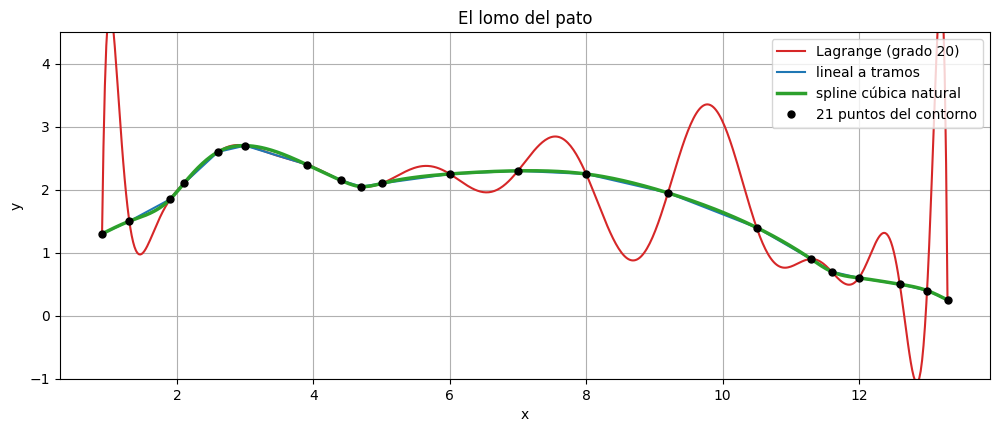

In [16]:
#tabla 3.18 de Burden y Faires: contorno superior del pato
x_pato = np.array([0.9, 1.3, 1.9, 2.1, 2.6, 3.0, 3.9, 4.4, 4.7, 5.0, 6.0,
                   7.0, 8.0, 9.2, 10.5, 11.3, 11.6, 12.0, 12.6, 13.0, 13.3])
y_pato = np.array([1.3, 1.5, 1.85, 2.1, 2.6, 2.7, 2.4, 2.15, 2.05, 2.1, 2.25,
                   2.3, 2.25, 1.95, 1.4, 0.9, 0.7, 0.6, 0.5, 0.4, 0.25])

xp = np.linspace(x_pato.min(), x_pato.max(), 600)

plt.figure(figsize=(12, 4.5))
plt.plot(xp, p_Lagrange(xp, x_pato, y_pato), color='tab:red', label='Lagrange (grado 20)')
plt.plot(xp, np.interp(xp, x_pato, y_pato), color='tab:blue', label='lineal a tramos')
plt.plot(xp, CubicSpline(x_pato, y_pato, bc_type='natural')(xp), color='tab:green', linewidth=2.5, label='spline cúbica natural')
plt.plot(x_pato, y_pato, 'o', color='black', markersize=5, label='21 puntos del contorno')
plt.ylim(-1, 4.5)
plt.title('El lomo del pato')
plt.xlabel('x')
plt.ylabel('y')
plt.legend(loc='upper right')
plt.show()

El polinomio de grado 20 pasa por los 21 puntos, pero entre ellos se sale por completo de la gráfica: es el fenómeno de Runge otra vez. La lineal a tramos sigue la forma general, pero con esquinas. La spline cúbica dibuja el lomo del pato casi igual que el original, suave y sin oscilaciones.

Por esto las splines son la herramienta estándar en diseño por computadora: tipografías, carrocerías de autos y animación.

#  Práctica con datos reales: temperatura mínima diaria en Melbourne

Ahora usaremos mediciones reales: la temperatura mínima diaria en Melbourne, Australia, de 1981 a 1990 (3650 días). Los datos son públicos y se descargan directamente desde una URL, sin necesidad de Google Drive.

El plan de la práctica es:

1. Descargar los datos y quedarnos con una ventana de 61 días.
2. Ocultar algunos días, como si el termómetro se hubiera descompuesto.
3. Reconstruir los días ocultos con los tres interpoladores.
4. Comparar contra los valores reales que escondimos, usando el ECM.

Es el mismo truco que se usa en aprendizaje automático para evaluar un modelo: se esconde una parte de los datos y se revisa qué tan bien la predice.

##  Descarga y lectura de los datos

In [17]:
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'

#pandas puede leer un csv directamente desde una URL
df = pd.read_csv(url, parse_dates=['Date'])
df.columns = ['Fecha', 'Temp']

print('Número de días:', df.shape[0])
print('Valores faltantes:', df['Temp'].isna().sum())
df.head()

Número de días: 3650
Valores faltantes: 0


,Fecha,Temp
0,1981-01-01,20.7
1,1981-01-02,17.9
2,1981-01-03,18.8
3,1981-01-04,14.6
4,1981-01-05,15.8


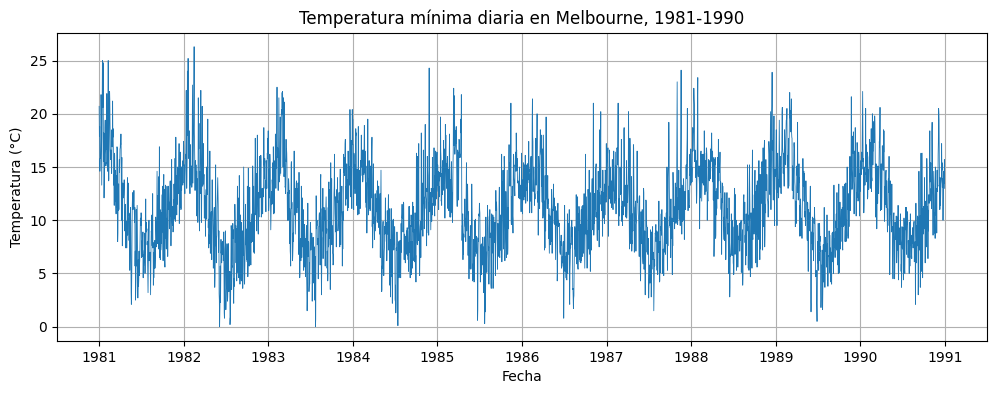

In [18]:
plt.figure(figsize=(12, 4))
plt.plot(df['Fecha'], df['Temp'], color='tab:blue', linewidth=0.6)
plt.title('Temperatura mínima diaria en Melbourne, 1981-1990')
plt.xlabel('Fecha')
plt.ylabel('Temperatura (°C)')
plt.show()

Se ve un patrón que se repite cada año: más calor a inicios y finales de año (verano en Australia) y más frío a mitad de año (invierno). Pero de un día a otro hay muchas subidas y bajadas irregulares: eso es ruido, variaciones que no siguen una curva suave.

## Ventana de trabajo y valores ocultos

Tomamos 61 días seguidos a partir del 1 de enero de 1990. De ellos conservamos un día de cada tres (21 días conocidos) y ocultamos los otros 40, que serán nuestra prueba.

Días conocidos: 21    Días ocultos: 40


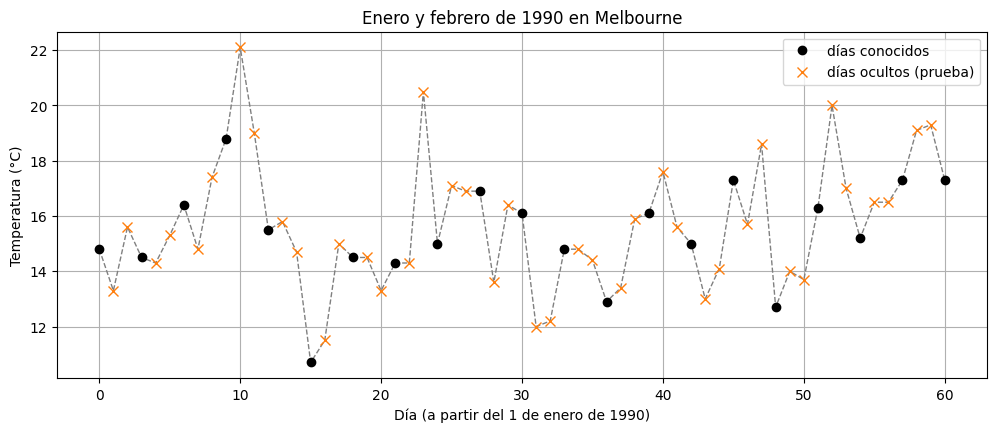

In [23]:
#ventana de 61 días a partir del 1 de enero de 1990
inicio  = df.index[df['Fecha'] == '1990-01-01'][0]
ventana = df.iloc[inicio:inicio + 61].reset_index(drop=True)

dias  = np.arange(len(ventana))          #día 0, 1, 2, ..., 60
temps = ventana['Temp'].values

#conservamos un día de cada 3 y ocultamos el resto
paso      = 3
conocidos = dias % paso == 0
ocultos   = ~conocidos

x_con, y_con = dias[conocidos], temps[conocidos]
x_ocu, y_ocu = dias[ocultos], temps[ocultos]
print('Días conocidos:', len(x_con), '   Días ocultos:', len(x_ocu))

plt.figure(figsize=(12, 4.5))
plt.plot(dias, temps, color='gray', linestyle='dashed', linewidth=1)
plt.plot(x_con, y_con, 'o', color='black', markersize=6, label='días conocidos')
plt.plot(x_ocu, y_ocu, 'x', color='tab:orange', markersize=7, label='días ocultos (prueba)')
plt.title('Enero y febrero de 1990 en Melbourne')
plt.xlabel('Día (a partir del 1 de enero de 1990)')
plt.ylabel('Temperatura (°C)')
plt.legend()
plt.show()


##  Reconstrucción de los días ocultos

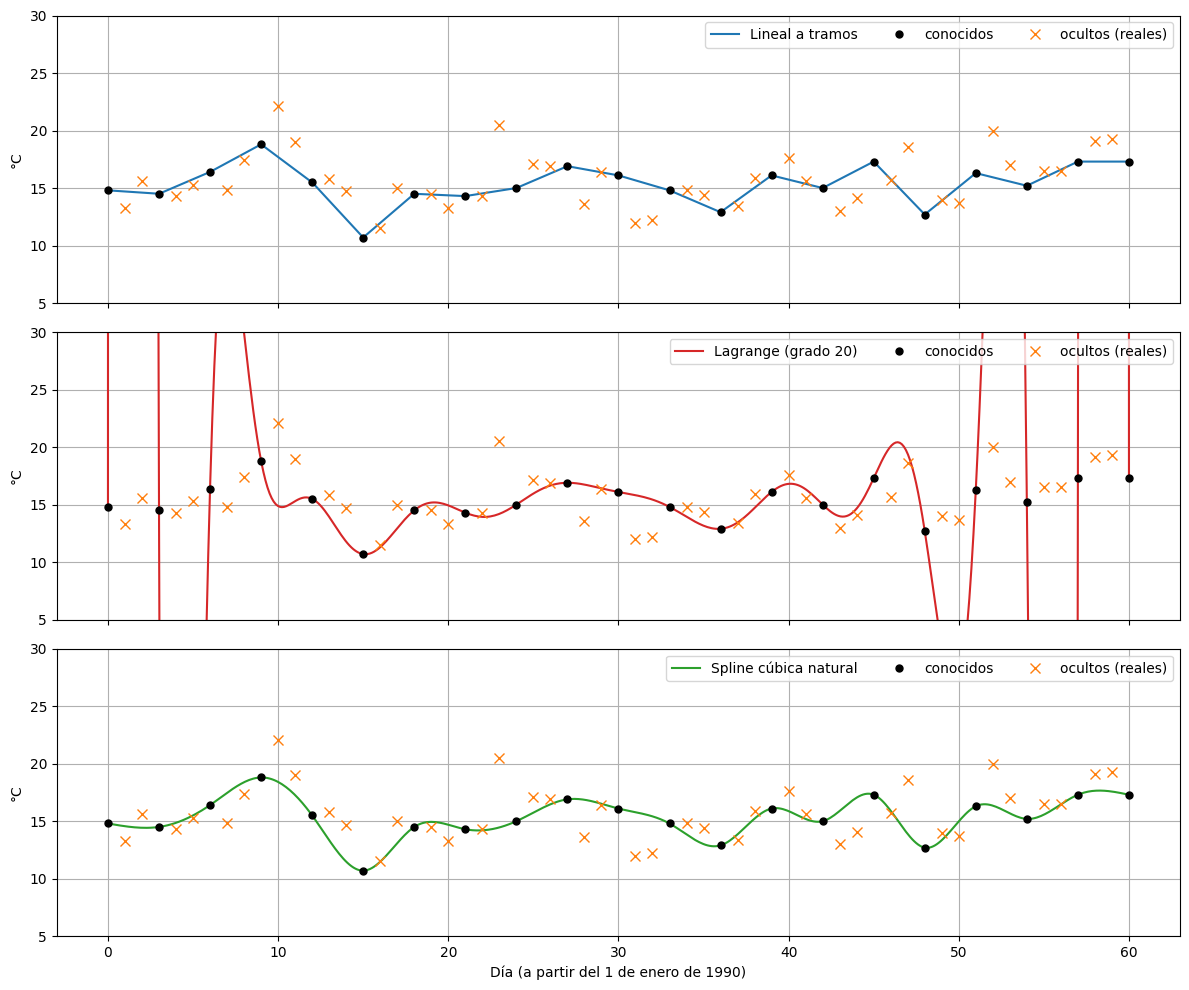

In [24]:
#estimamos los días ocultos con cada interpolador
est_lineal   = np.interp(x_ocu, x_con, y_con)
est_lagrange = p_Lagrange(x_ocu, x_con, y_con)
est_spline   = CubicSpline(x_con, y_con, bc_type='natural')(x_ocu)

#curvas completas para dibujar
x_dib = np.linspace(0, dias.max(), 500)

fig, ejes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
curvas = [('Lineal a tramos', np.interp(x_dib, x_con, y_con), 'tab:blue'),
          ('Lagrange (grado 20)', p_Lagrange(x_dib, x_con, y_con), 'tab:red'),
          ('Spline cúbica natural', CubicSpline(x_con, y_con, bc_type='natural')(x_dib), 'tab:green')]
for eje, (nombre, y_dib, color) in zip(ejes, curvas):
    eje.plot(x_dib, y_dib, color=color, label=nombre)
    eje.plot(x_con, y_con, 'o', color='black', markersize=5, label='conocidos')
    eje.plot(x_ocu, y_ocu, 'x', color='tab:orange', markersize=7, label='ocultos (reales)')
    eje.set_ylim(5, 30)
    eje.set_ylabel('°C')
    eje.legend(loc='upper right', ncol=3)
ejes[-1].set_xlabel('Día (a partir del 1 de enero de 1990)')
plt.tight_layout()
plt.show()

## Evaluación con el error cuadrático medio

Comparamos las estimaciones contra los 40 valores reales que ocultamos.

In [25]:
resultados = pd.DataFrame({
    'Interpolador': ['Lineal a tramos', 'Lagrange (grado 20)', 'Spline cúbica'],
    'ECM': [ecm(y_ocu, est_lineal), ecm(y_ocu, est_lagrange), ecm(y_ocu, est_spline)]
})
resultados['Error típico (°C)'] = np.sqrt(resultados['ECM'])
resultados.round(2)

,Interpolador,ECM,Error típico (°C)
0,Lineal a tramos,4.57,2.14
1,Lagrange (grado 20),918873.10,958.58
2,Spline cúbica,4.83,2.20


La raíz del ECM (error típico) está en grados, así que es más fácil de leer: indica más o menos cuántos grados se equivoca cada método en un día oculto.

Lagrange tiene un error enorme. Con 21 puntos su polinomio es de grado 20 y, además de Runge, intenta pasar exactamente por un ruido que sube y baja sin orden: en los bordes de la ventana sus estimaciones se van a valores imposibles para una temperatura.

Entre la lineal a tramos y la spline la diferencia es pequeña, y en este caso la lineal gana por poco. Con datos tan ruidosos, la suavidad de la spline no siempre ayuda: si la temperatura brinca de un día a otro, una curva suave puede pasarse de largo entre dos datos, mientras que la recta solo promedia a sus vecinos.

##  ¿Qué pasa si ocultamos más días?

Repetimos el experimento conservando un día de cada 2, 3, 4, 5 y 7. Dejamos fuera a Lagrange porque su error es demasiado grande para compararlo en la misma gráfica.

 Un día de cada  ECM lineal  ECM spline   Error tipico(lineal)   Error tipico(spline)
              2        3.33        3.56                   1.83                   1.89
              3        4.57        4.83                   2.14                   2.20
              4        5.69        6.89                   2.39                   2.63
              5        4.52        6.09                   2.13                   2.47
              7        6.09        6.08                   2.47                   2.47


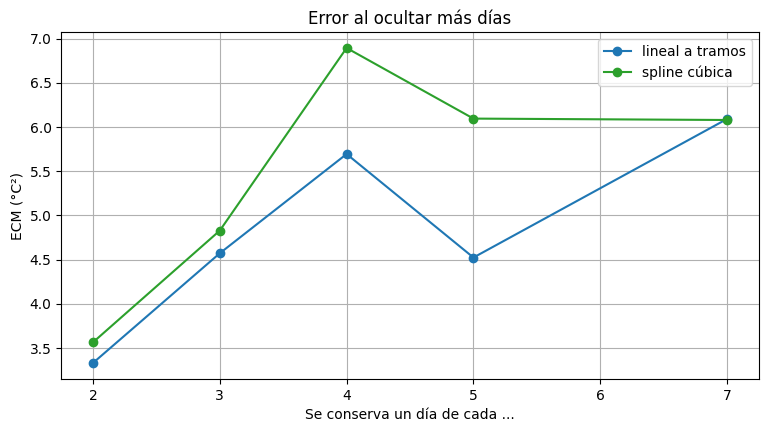

In [30]:
pasos = [2, 3, 4, 5, 7]
ecm_lin, ecm_spl = [], []
for p in pasos:
    con = dias % p == 0
    ocu = ~con
    ecm_lin.append(ecm(temps[ocu], np.interp(dias[ocu], dias[con], temps[con])))
    ecm_spl.append(ecm(temps[ocu], CubicSpline(dias[con], temps[con], bc_type='natural')(dias[ocu])))

print(pd.DataFrame({'Un día de cada': pasos, 'ECM lineal': ecm_lin, 'ECM spline': ecm_spl, ' Error tipico(lineal)': np.sqrt(ecm_lin), ' Error tipico(spline)': np.sqrt(ecm_spl)}).round(2).to_string(index=False))

plt.plot(pasos, ecm_lin, 'o-', color='tab:blue', label='lineal a tramos')
plt.plot(pasos, ecm_spl, 'o-', color='tab:green', label='spline cúbica')
plt.title('Error al ocultar más días')
plt.xlabel('Se conserva un día de cada ...')
plt.ylabel('ECM (°C²)')
plt.legend()
plt.show()

En general, entre menos días conocemos, más grande es el error: los huecos son más largos y la temperatura tiene más tiempo para cambiar sin que la veamos. La subida no es pareja porque el resultado depende de qué días quedaron ocultos; con tan pocos datos de prueba, un solo día raro mueve mucho el ECM. La interpolación funciona bien para rellenar huecos cortos, pero ningún método puede adivinar lo que pasó en una semana entera sin datos.


# Campos de aplicación

La interpolación aparece en muchos lugares, aunque casi nunca la veamos:

- Ciencia de datos y aprendizaje automático: rellenar valores faltantes en series de tiempo (imputación), como hicimos con la temperatura.
- Meteorología y ciencias de la Tierra: estimar la temperatura o la lluvia en lugares donde no hay estación de medición, a partir de las estaciones cercanas.
- Gráficos por computadora y diseño: tipografías, curvas de Bézier, carrocerías de autos y trayectorias en animación se construyen con splines.
- Imágenes digitales: al hacer zoom o cambiar el tamaño de una foto, los pixeles nuevos se calculan interpolando los vecinos (bilineal, bicúbica).
- Finanzas y actuaría: construir curvas de tasas de interés y tablas de mortalidad a partir de pocos plazos o edades observados.
- Ingeniería y robótica: trayectorias suaves para brazos robóticos y lecturas de sensores entre mediciones.
- Audio: cambiar la frecuencia de muestreo de una grabación.
- Métodos numéricos: muchas fórmulas de derivación e integración numérica se obtienen derivando o integrando un polinomio interpolante.

# Conclusiones

- La interpolación lineal a tramos es simple y robusta, pero deja esquinas.
- Un solo polinomio de Lagrange funciona con pocos puntos, pero con muchos puntos igualmente espaciados oscila en los bordes (fenómeno de Runge).
- Las splines cúbicas trabajan por tramos y empalman suavemente, por eso evitan las oscilaciones y reconstruyen formas como el lomo del pato.
- Con datos reales y ruidosos, pasar exactamente por todos los puntos no siempre es buena idea. Para evaluar un interpolador hay que esconder datos y medir el error, igual que con cualquier modelo de aprendizaje automático.-
  